# 01 — EDA & Data Wrangling · Service 3 `audio-engine`

**Objectif :** comprendre les données avant de les transformer.

Ce notebook **ne modifie aucun fichier**. Il lit :
- `data/processed/inventory.csv`, produit par `python -m scripts.prepare_data` ;
- quelques audios d'exemple dans `data/raw/`.

| # | Section | Question |
|---|---|---|
| 0 | Configuration | — |
| 1 | Vue d'ensemble | Combien d'audios, de quelles sources ? |
| 2 | Classes | Les données sont-elles équilibrées ? |
| 3 | Fréquences d'échantillonnage | Pourquoi rééchantillonner ? |
| 4 | Durées | Quelle variabilité ? |
| 5 | **Choix 2 s ou 5 s** | Quelle durée de segment retenir ? |
| 6 | Découpage train/val/test | Le split est-il correct ? |
| 7 | Écoute et forme d'onde | À quoi ressemble un battement ? |
| 8 | Effet du rééchantillonnage | Que perd-on en passant à 2000 Hz ? |
| 9 | Spectrogramme et Mel | Ce que verront les CNN |
| 10 | MFCC et ZCR | Ce que verront le Decision Tree et le SVM |
| 11 | Normal vs anormal | Voit-on une différence ? |
| 12 | Synthèse | Conclusions |

> Ici, le rééchantillonnage est appliqué à **un seul exemple**, pour le visualiser. Le vrai prétraitement de tous les audios se fera à l'Étape 2 (`src/preprocessing.py`).

In [1]:
import sys
print(sys.executable)

c:\Users\bouch\Desktop\CardioAgent-Ops\audio_engine\.venv\Scripts\python.exe


## 0. Configuration

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio, display

# Le notebook est dans notebooks/ : on ajoute la racine du module pour importer src/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import INVENTORY_PATH, RAW_DIR, RANDOM_SEED

# Paramètres imposés par le cahier des charges [A]
TARGET_SR = 2000                 # rééchantillonnage à 2000 Hz
CANDIDATE_SEGMENTS = [2, 5]      # segments de 2 s ou 5 s

# Paramètres provisoires pour les visualisations [C] (fixés définitivement à l'étape 3)
N_FFT, HOP_LENGTH = 256, 64      # fenêtre de 128 ms, pas de 32 ms à 2000 Hz
N_MELS, N_MFCC = 32, 13

COLORS = {"normal": "tab:green", "abnormal": "tab:red"}
ORDER = ["normal", "abnormal"]
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

print("Racine du projet :", PROJECT_ROOT)
print("librosa", librosa.__version__, "| pandas", pd.__version__)

Racine du projet : c:\Users\bouch\Desktop\CardioAgent-Ops\audio_engine
librosa 1.0.0 | pandas 3.0.6


## 1. Vue d'ensemble

In [3]:
df = pd.read_csv(INVENTORY_PATH)
print(f"{len(df)} audios | {df['group_id'].nunique()} groupes | {df['source'].nunique()} sources")
print(f"Fichiers invalides : {(~df['valid']).sum()} | canaux : {df['n_channels'].unique().tolist()}")
df.head()

3784 audios | 3487 groupes | 3 sources
Fichiers invalides : 0 | canaux : [1]


,path,filename,label,label_name,source,group_id,sample_rate,n_channels,duration_s,valid,split
0,ourdataset/train/normal/101_1305030823364_B.wav,101_1305030823364_B.wav,0,normal,pascal_B,pascal_B:101,4000,1,8.807,True,val
1,ourdataset/train/normal/101_1305030823364_E.wav,101_1305030823364_E.wav,0,normal,pascal_B,pascal_B:101,4000,1,4.681,True,val
2,ourdataset/train/normal/103_1305031931979_B.wav,103_1305031931979_B.wav,0,normal,pascal_B,pascal_B:103,4000,1,6.210,True,train
3,ourdataset/train/normal/103_1305031931979_D1.wav,103_1305031931979_D1.wav,0,normal,pascal_B,pascal_B:103,4000,1,9.902,True,train
4,ourdataset/train/normal/103_1305031931979_D2.wav,103_1305031931979_D2.wav,0,normal,pascal_B,pascal_B:103,4000,1,5.120,True,train


In [4]:
overview = pd.crosstab(df["source"], df["label_name"], margins=True, margins_name="Total")[ORDER + ["Total"]]
overview

label_name,normal,abnormal,Total
source,,,
pascal_A,31,52,83
pascal_B,320,141,461
physionet2016,2575,665,3240
Total,2926,858,3784


**Lecture :** chaque ligne de l'inventaire est un audio. Les trois sources (PhysioNet 2016, PASCAL A, PASCAL B) ont été identifiées par leur fréquence d'échantillonnage. PhysioNet représente la grande majorité du dataset.

## 2. Distribution des classes

,n_audios,pourcentage
label_name,,
normal,2926,77.3
abnormal,858,22.7


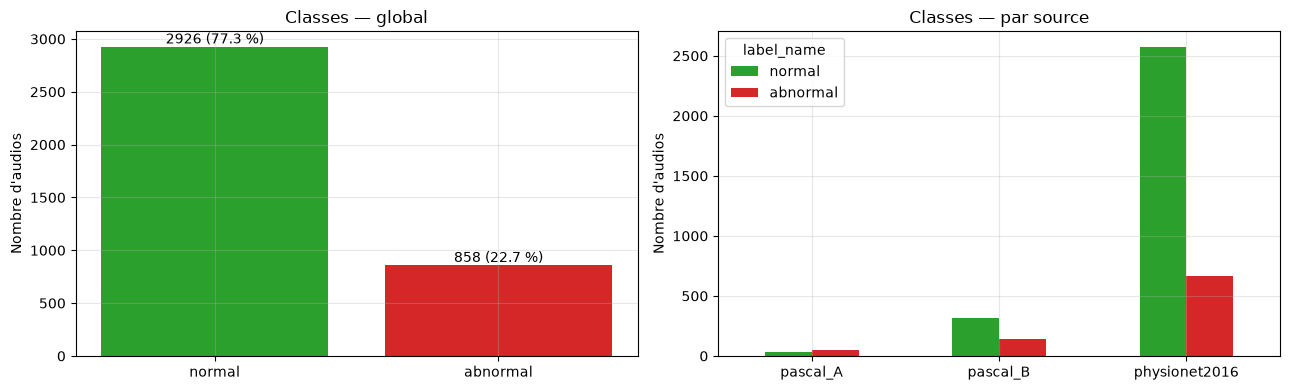

In [5]:
counts = df["label_name"].value_counts().reindex(ORDER)
pct = (counts / len(df) * 100).round(1)
display(pd.DataFrame({"n_audios": counts, "pourcentage": pct}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(ORDER, counts, color=[COLORS[c] for c in ORDER])
for i, (n, p) in enumerate(zip(counts, pct)):
    axes[0].text(i, n, f"{n} ({p} %)", ha="center", va="bottom")
axes[0].set(title="Classes — global", ylabel="Nombre d'audios")

pd.crosstab(df["source"], df["label_name"])[ORDER].plot.bar(
    ax=axes[1], color=[COLORS[c] for c in ORDER], rot=0)
axes[1].set(title="Classes — par source", ylabel="Nombre d'audios", xlabel="")
plt.tight_layout(); plt.show()

**Lecture :** la classe `abnormal` (pathologique) est minoritaire. Un modèle qui répondrait toujours « normal » aurait une accuracy élevée, sans rien détecter. C'est pour cela que :
- le cahier des charges impose de sélectionner le modèle sur le **Recall de la classe pathologique** ;
- le **rééquilibrage** sera appliqué au jeu d'entraînement uniquement.

## 3. Fréquences d'échantillonnage

sample_rate,2000,4000,44100,Total
source,,,,
pascal_A,0,0,83,83
pascal_B,0,461,0,461
physionet2016,3240,0,0,3240
Total,3240,461,83,3784


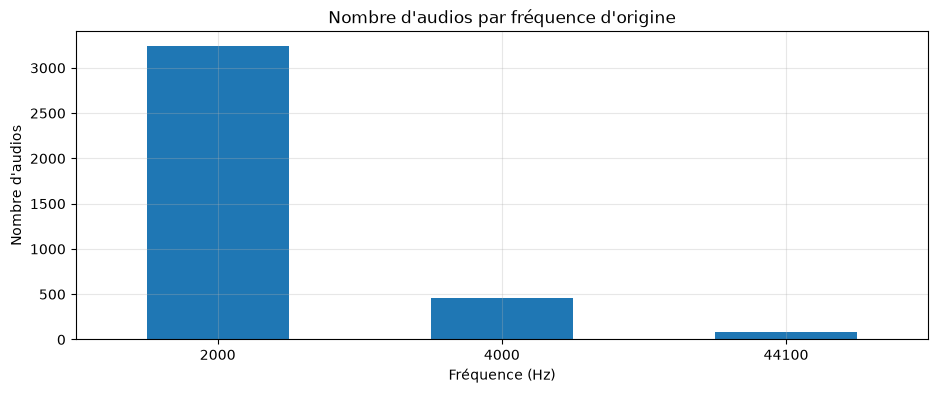

In [6]:
sr_table = pd.crosstab(df["source"], df["sample_rate"], margins=True, margins_name="Total")
display(sr_table)

ax = df["sample_rate"].value_counts().sort_index().plot.bar(rot=0, color="tab:blue")
ax.set(title="Nombre d'audios par fréquence d'origine", xlabel="Fréquence (Hz)", ylabel="Nombre d'audios")
plt.show()

**Lecture :** trois fréquences différentes coexistent (2000, 4000 et 44100 Hz). Un même son de 5 s représente 10 000, 20 000 ou 220 500 valeurs selon la source. Il faut donc tout ramener à **2000 Hz**, comme l'exige le cahier des charges, avant d'extraire les caractéristiques. L'effet est visualisé en section 8.

## 4. Durées des enregistrements

,count,min,25%,50%,75%,max,mean
source,,,,,,,
pascal_A,83.0,0.936,7.81800,7.936,8.884,9.000,7.624434
pascal_B,461.0,0.763,2.97400,5.090,9.315,27.867,6.479004
physionet2016,3240.0,5.306,12.89925,20.828,30.581,121.999,22.461748


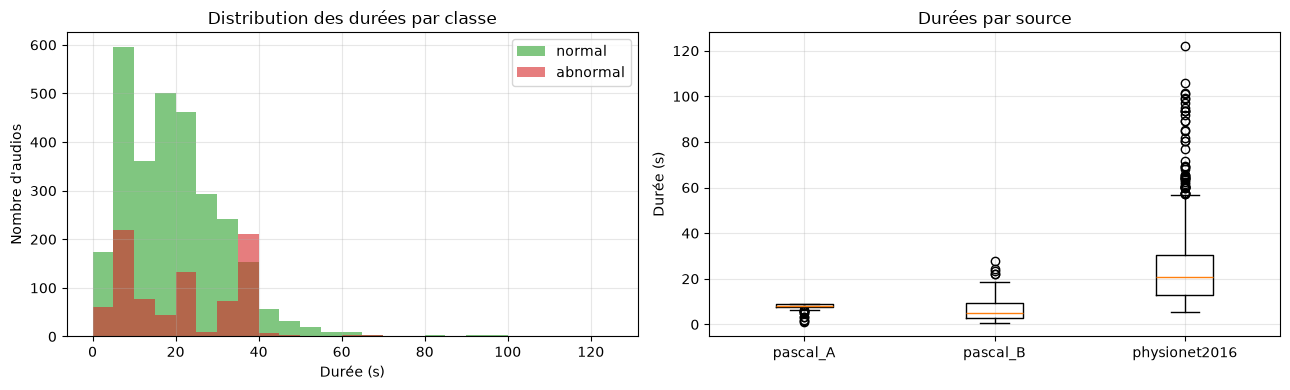

In [7]:
display(df.groupby("source")["duration_s"].describe()[["count", "min", "25%", "50%", "75%", "max", "mean"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.arange(0, df["duration_s"].max() + 5, 5)
for name in ORDER:
    axes[0].hist(df.loc[df["label_name"] == name, "duration_s"], bins=bins,
                 alpha=0.6, label=name, color=COLORS[name])
axes[0].set(title="Distribution des durées par classe", xlabel="Durée (s)", ylabel="Nombre d'audios")
axes[0].legend()

sources = sorted(df["source"].unique())
axes[1].boxplot([df.loc[df["source"] == s, "duration_s"] for s in sources])
axes[1].set_xticks(range(1, len(sources) + 1), sources)
axes[1].set(title="Durées par source", ylabel="Durée (s)")
plt.tight_layout(); plt.show()

**Lecture :** les durées varient énormément (de moins d'une seconde à plus de deux minutes). Les modèles ont besoin d'entrées de taille fixe : c'est la **normalisation de durée** (2 s ou 5 s) demandée par le cahier des charges. La section suivante aide à choisir.

## 5. Choisir entre des segments de 2 s et de 5 s

Le cahier des charges autorise **2 s ou 5 s** [A]. Le choix nous revient [C]. Chaque audio sera découpé en fenêtres de cette durée (sans chevauchement dans ce calcul).

Trois critères :
1. **Contenu médical** : au repos, un cycle cardiaque dure environ 0,6 à 1 s. Une fenêtre de 2 s contient donc 2 à 3 cycles, et une fenêtre de 5 s en contient 5 à 8. Le cahier des charges demande de capter la structure temporelle des bruits B1 et B2 : plus de cycles, c'est plus de contexte.
2. **Audios perdus** : un audio plus court que la fenêtre ne donne aucun segment, sauf si on le complète (padding).
3. **Nombre d'exemples** : des fenêtres plus courtes donnent plus de segments pour entraîner.

In [8]:
rows = []
is_abn = df["label"] == 1
for seg in CANDIDATE_SEGMENTS:
    n_seg = np.floor(df["duration_s"] / seg).astype(int)
    too_short = df["duration_s"] < seg
    rows.append({
        "segment_s": seg,
        "audios_trop_courts": int(too_short.sum()),
        "dont_abnormal": int((too_short & is_abn).sum()),
        "pct_audios_perdus": round(too_short.mean() * 100, 1),
        "segments_total": int(n_seg.sum()),
        "segments_abnormal": int(n_seg[is_abn].sum()),
        "pct_segments_abnormal": round(n_seg[is_abn].sum() / n_seg.sum() * 100, 1),
    })
display(pd.DataFrame(rows).set_index("segment_s"))

print("Audios trop courts, par source :")
display(pd.DataFrame({f"< {s} s": (df["duration_s"] < s).groupby(df["source"]).sum()
                      for s in CANDIDATE_SEGMENTS}))

,audios_trop_courts,dont_abnormal,pct_audios_perdus,segments_total,segments_abnormal,pct_segments_abnormal
segment_s,,,,,,
2,57,7,1.5,36505,8780,24.1
5,234,61,6.2,13454,3337,24.8


Audios trop courts, par source :


,< 2 s,< 5 s
source,,
pascal_A,3,7
pascal_B,54,227
physionet2016,0,0


## 6. Vérification du découpage train / validation / test

In [9]:
split_order = ["train", "val", "test"]
used = df[df["split"] != "excluded"]
print("Pourcentage de chaque classe dans chaque ensemble :")
display((pd.crosstab(used["split"], used["label_name"], normalize="index") * 100).round(1).reindex(split_order)[ORDER])
print("Nombre d'audios par source et par ensemble :")
display(pd.crosstab(used["source"], used["split"])[split_order])

groups_per_split = used.groupby("group_id")["split"].nunique()
print("Groupes présents dans plusieurs ensembles (doit être 0) :", int((groups_per_split > 1).sum()))

Pourcentage de chaque classe dans chaque ensemble :


label_name,normal,abnormal
split,,
train,77.3,22.7
val,77.4,22.6
test,77.3,22.7


Nombre d'audios par source et par ensemble :


split,train,val,test
source,,,
pascal_A,58,12,13
pascal_B,330,66,65
physionet2016,2314,463,463


Groupes présents dans plusieurs ensembles (doit être 0) : 0


**Lecture :** la proportion de cas pathologiques est la même dans les trois ensembles (stratification), et aucun groupe n'est partagé entre deux ensembles (pas de data leakage).

## 7. Écoute et forme d'onde (waveform)

La **forme d'onde** montre l'amplitude du son au cours du temps. Sur un cœur normal, on reconnaît le rythme « lub-dub » : **B1** (fermeture des valves mitrale et tricuspide), puis **B2** (fermeture des valves aortique et pulmonaire). Un souffle (murmur) apparaît comme une agitation **entre** B1 et B2.

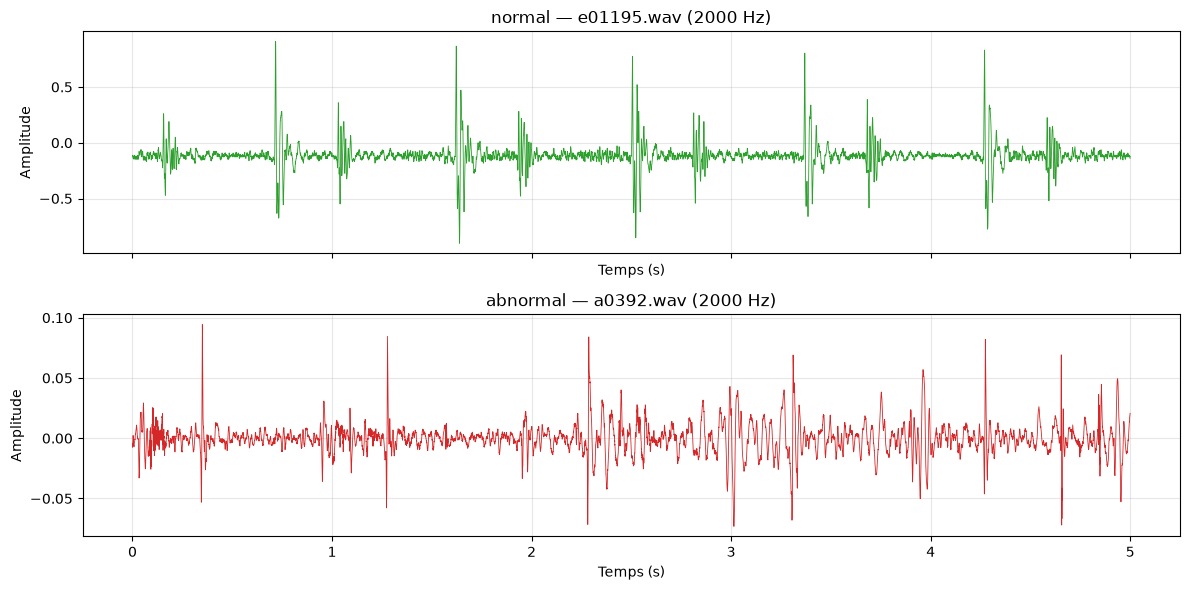

normal


abnormal


In [10]:
def pick_example(source: str, label: int, min_duration: float = 5.0) -> pd.Series:
    """Choisit un audio au hasard (de façon reproductible) parmi une source et une classe."""
    candidates = df[(df["source"] == source) & (df["label"] == label) & (df["duration_s"] >= min_duration)]
    if candidates.empty:  # repli si aucun audio n'est assez long
        candidates = df[(df["source"] == source) & (df["label"] == label)]
    return candidates.sample(1, random_state=RANDOM_SEED).iloc[0]


def load_raw(row: pd.Series) -> tuple[np.ndarray, int]:
    """Charge un audio à sa fréquence d'origine (sr=None : aucun rééchantillonnage)."""
    y, sr = librosa.load(RAW_DIR / row["path"], sr=None, mono=True)
    return y, sr


def play(y: np.ndarray, sr: int):
    """Lecteur audio. Beaucoup de lecteurs refusent les sons à 2000 Hz :
    on convertit à 8000 Hz uniquement pour l'écoute."""
    if sr < 8000:
        y, sr = librosa.resample(y, orig_sr=sr, target_sr=8000), 8000
    return Audio(y, rate=sr)


def plot_waveform(ax, y: np.ndarray, sr: int, title: str, seconds: float = 5.0) -> None:
    n = int(min(len(y), seconds * sr))
    ax.plot(np.arange(n) / sr, y[:n], linewidth=0.6)
    ax.set(title=title, xlabel="Temps (s)", ylabel="Amplitude")


examples = {name: pick_example("physionet2016", label) for name, label in [("normal", 0), ("abnormal", 1)]}
signals = {name: load_raw(row) for name, row in examples.items()}

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, name in zip(axes, ORDER):
    y, sr = signals[name]
    plot_waveform(ax, y, sr, f"{name} — {examples[name]['filename']} ({sr} Hz)")
    ax.get_lines()[0].set_color(COLORS[name])
plt.tight_layout(); plt.show()

for name in ORDER:
    print(name); display(play(*signals[name]))

## 8. Effet du rééchantillonnage (sur un seul exemple)

On prend un audio de **PASCAL A (44100 Hz)**, la source la plus éloignée de 2000 Hz, et on le rééchantillonne avec `librosa.resample`. Librosa applique un **filtre anti-repliement** avant de réduire le nombre d'échantillons.

**Règle de Nyquist :** à 2000 Hz, on peut représenter les fréquences jusqu'à **1000 Hz**. On vérifie ci-dessous quelle part de l'énergie du signal se trouve au-dessus de cette limite, c'est-à-dire ce qu'on perd.

Fichier : 201108011115.wav
Avant : 44100 Hz,  349958 échantillons, durée 7.94 s
Après : 2000 Hz,   15872 échantillons, durée 7.94 s
Le signal est 22.0 fois plus léger, pour la même durée.


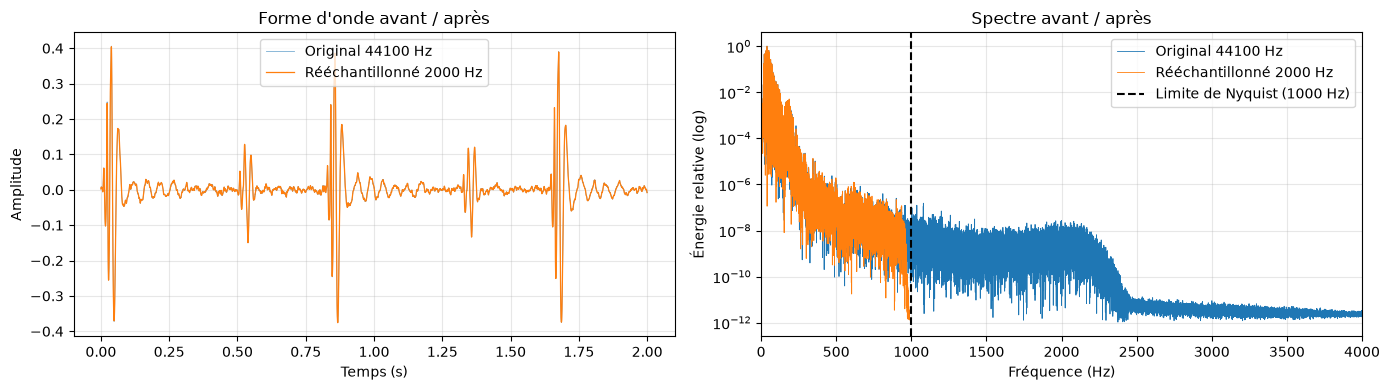

Énergie au-dessus de 1000 Hz dans l'original : 0.00 %


In [11]:
row_a = pick_example("pascal_A", 0)
y_orig, sr_orig = load_raw(row_a)
y_2k = librosa.resample(y_orig, orig_sr=sr_orig, target_sr=TARGET_SR)

print(f"Fichier : {row_a['filename']}")
print(f"Avant : {sr_orig} Hz, {len(y_orig):>7} échantillons, durée {len(y_orig) / sr_orig:.2f} s")
print(f"Après : {TARGET_SR} Hz, {len(y_2k):>7} échantillons, durée {len(y_2k) / TARGET_SR:.2f} s")
print(f"Le signal est {len(y_orig) / len(y_2k):.1f} fois plus léger, pour la même durée.")


def power_spectrum(y: np.ndarray, sr: int) -> tuple[np.ndarray, np.ndarray]:
    """Spectre de puissance moyen (énergie par fréquence) sur tout le signal."""
    spectrum = np.abs(np.fft.rfft(y)) ** 2
    return np.fft.rfftfreq(len(y), d=1 / sr), spectrum


def energy_above(y: np.ndarray, sr: int, cutoff: float = TARGET_SR / 2) -> float:
    freqs, power = power_spectrum(y, sr)
    return power[freqs > cutoff].sum() / power.sum()


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
window = 2.0  # secondes affichées
n_o, n_r = int(window * sr_orig), int(window * TARGET_SR)
axes[0].plot(np.arange(n_o) / sr_orig, y_orig[:n_o], lw=0.6, alpha=0.6, label=f"Original {sr_orig} Hz")
axes[0].plot(np.arange(n_r) / TARGET_SR, y_2k[:n_r], lw=0.9, label=f"Rééchantillonné {TARGET_SR} Hz")
axes[0].set(title="Forme d'onde avant / après", xlabel="Temps (s)", ylabel="Amplitude")
axes[0].legend()

for y, sr, label in [(y_orig, sr_orig, f"Original {sr_orig} Hz"), (y_2k, TARGET_SR, f"Rééchantillonné {TARGET_SR} Hz")]:
    freqs, power = power_spectrum(y, sr)
    axes[1].semilogy(freqs, power / power.max() + 1e-12, lw=0.6, label=label)
axes[1].axvline(TARGET_SR / 2, color="k", ls="--", label="Limite de Nyquist (1000 Hz)")
axes[1].set(title="Spectre avant / après", xlabel="Fréquence (Hz)", ylabel="Énergie relative (log)", xlim=(0, 4000))
axes[1].legend()
plt.tight_layout(); plt.show()

print(f"Énergie au-dessus de 1000 Hz dans l'original : {energy_above(y_orig, sr_orig) * 100:.2f} %")

Le même calcul sur **tous les audios PASCAL** (les seuls concernés par le rééchantillonnage) donne une mesure globale de l'information perdue. Le chargement prend quelques dizaines de secondes.

In [12]:
pascal = df[df["source"].str.startswith("pascal")]
loss = pd.Series({row["path"]: energy_above(*load_raw(row)) for _, row in pascal.iterrows()})
pascal = pascal.assign(energie_perdue_pct=(loss.reindex(pascal["path"]).values * 100))
display(pascal.groupby("source")["energie_perdue_pct"].describe()[["mean", "50%", "max"]].round(2))

,mean,50%,max
source,,,
pascal_A,1.05,0.16,14.53
pascal_B,0.47,0.11,12.96


**Lecture :** l'essentiel de l'énergie des sons cardiaques est en dessous de 1000 Hz. Le rééchantillonnage à 2000 Hz garde donc l'information utile, uniformise les trois sources et allège fortement les calculs. Les rares audios qui perdent beaucoup d'énergie contiennent surtout du bruit aigu.

## 9. Spectrogramme et Mel-spectrogramme

À partir d'ici, on travaille sur l'exemple **normal à 2000 Hz** (5 premières secondes).

- **Spectrogramme** : image temps (x) × fréquence (y), où la couleur représente l'énergie. On l'obtient par une transformée de Fourier sur des fenêtres glissantes (STFT). Un CNN peut le traiter comme une image.
- **Mel-spectrogramme** : même idée, mais l'axe des fréquences suit l'**échelle Mel**, qui imite l'oreille humaine. Elle est plus fine dans les graves et plus grossière dans les aigus, et elle regroupe les fréquences en un petit nombre de bandes. L'image est plus compacte, et l'information des basses fréquences, où se trouvent les bruits cardiaques, est mieux détaillée. C'est l'entrée imposée pour le CNN Custom 2D [A].

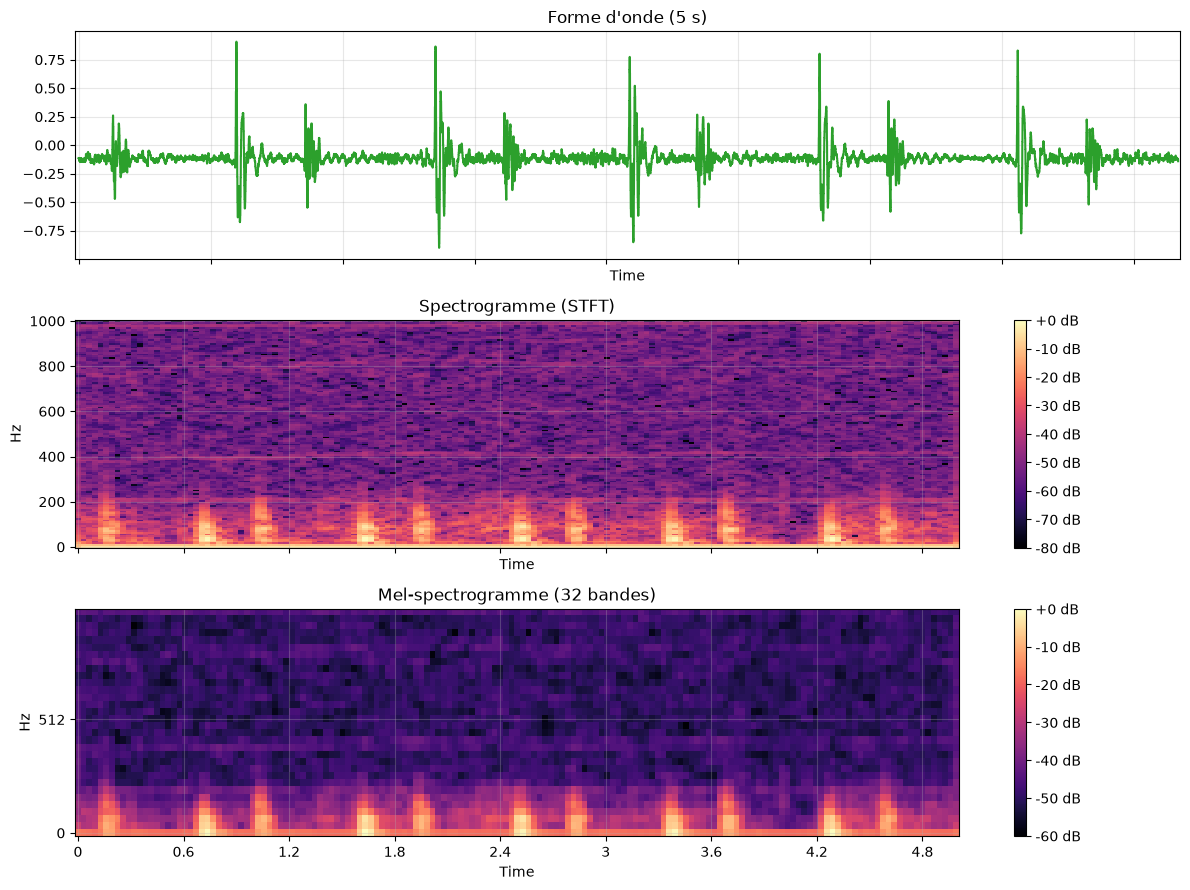

Spectrogramme : (129, 157) -> (fréquences, instants)
Mel-spectrogramme : (32, 157) -> (bandes Mel, instants)  <- l'« image » d'entrée du CNN


In [13]:
y, sr = signals["normal"]
y5 = y[: 5 * sr]

stft_db = librosa.amplitude_to_db(np.abs(librosa.stft(y5, n_fft=N_FFT, hop_length=HOP_LENGTH)), ref=np.max)
mel_db = librosa.power_to_db(
    librosa.feature.melspectrogram(y=y5, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH,
                                   n_mels=N_MELS, fmax=sr / 2),
    ref=np.max)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
librosa.display.waveshow(y5, sr=sr, ax=axes[0], color=COLORS["normal"])
axes[0].set(title="Forme d'onde (5 s)")
img1 = librosa.display.specshow(stft_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="hz", ax=axes[1])
axes[1].set(title="Spectrogramme (STFT)")
img2 = librosa.display.specshow(mel_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", fmax=sr / 2, ax=axes[2])
axes[2].set(title=f"Mel-spectrogramme ({N_MELS} bandes)")
fig.colorbar(img1, ax=axes[1], format="%+2.0f dB"); fig.colorbar(img2, ax=axes[2], format="%+2.0f dB")
plt.tight_layout(); plt.show()

print(f"Spectrogramme : {stft_db.shape} -> (fréquences, instants)")
print(f"Mel-spectrogramme : {mel_db.shape} -> (bandes Mel, instants)  <- l'« image » d'entrée du CNN")

## 10. MFCC et ZCR

- **MFCC** (Mel-Frequency Cepstral Coefficients) : une description compacte de la « forme » du spectre, en quelques coefficients (ici 13) par instant. On les calcule à partir du Mel-spectrogramme. Pour le Decision Tree et le SVM, on résumera chaque segment par la moyenne et l'écart-type de chaque coefficient, ce qui donne un **vecteur 1D** [A : « caractéristiques 1D (MFCC) »].
- **ZCR** (Zero-Crossing Rate) : le nombre de fois où le signal passe par zéro, par unité de temps. Il est élevé pour un signal bruité ou aigu (souffle, bruit de frottement), et faible pour les bruits cardiaques graves.

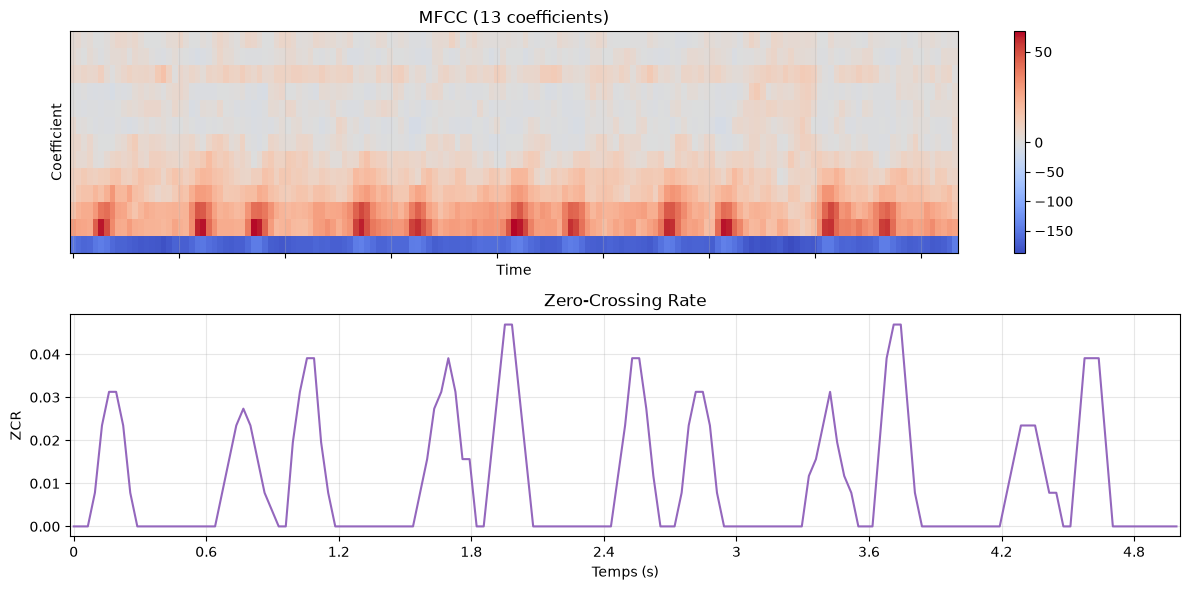

MFCC : (13, 157) -> (coefficients, instants)
ZCR  : (157,) -> une valeur par instant
Exemple de vecteur 1D pour DT/SVM : 28 valeurs (13 moyennes + 13 écarts-types + 2 ZCR)


In [14]:
mfcc = librosa.feature.mfcc(y=y5, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH,
                            n_mels=N_MELS, fmax=sr / 2)
zcr = librosa.feature.zero_crossing_rate(y5, frame_length=N_FFT, hop_length=HOP_LENGTH)[0]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
img = librosa.display.specshow(mfcc, sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=axes[0])
axes[0].set(title=f"MFCC ({N_MFCC} coefficients)", ylabel="Coefficient")
fig.colorbar(img, ax=axes[0])
axes[1].plot(librosa.times_like(zcr, sr=sr, hop_length=HOP_LENGTH), zcr, color="tab:purple")
axes[1].set(title="Zero-Crossing Rate", xlabel="Temps (s)", ylabel="ZCR")
plt.tight_layout(); plt.show()

feature_vector = np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1), [zcr.mean(), zcr.std()]])
print(f"MFCC : {mfcc.shape} -> (coefficients, instants)")
print(f"ZCR  : {zcr.shape} -> une valeur par instant")
print(f"Exemple de vecteur 1D pour DT/SVM : {feature_vector.shape[0]} valeurs (13 moyennes + 13 écarts-types + 2 ZCR)")

## 11. Comparaison normal / anormal

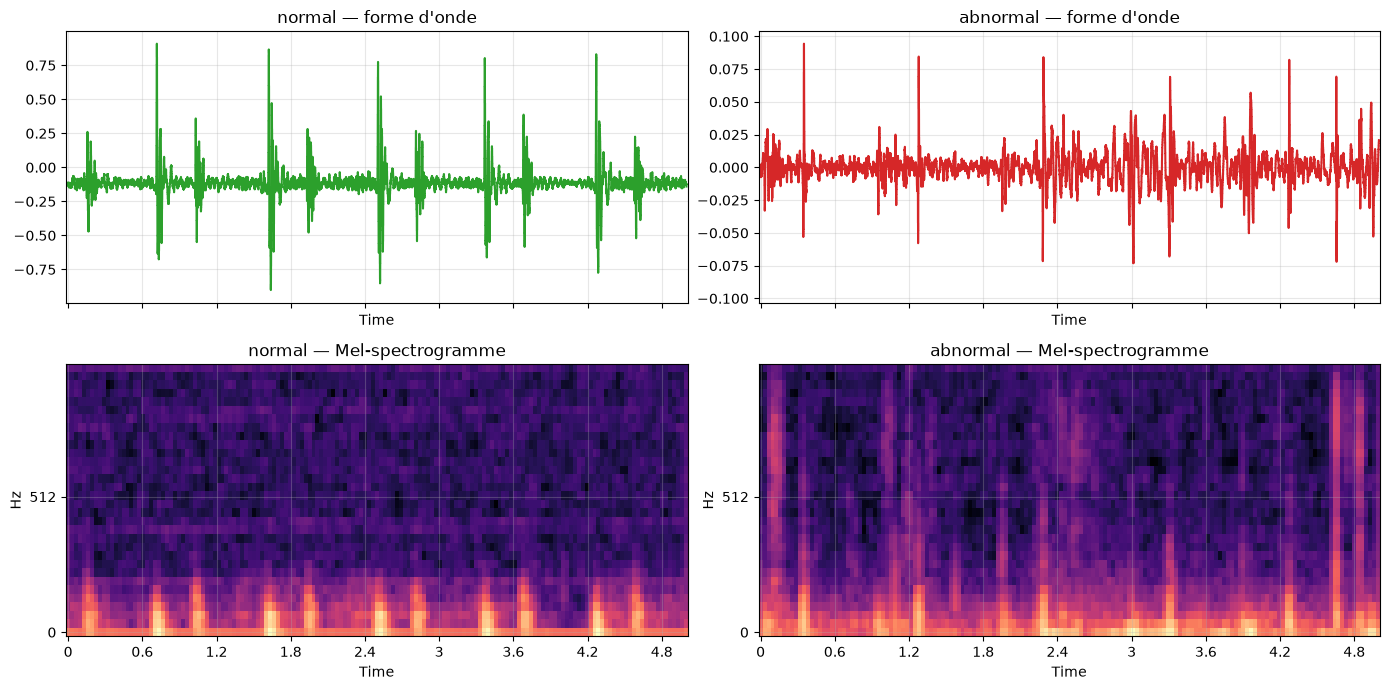

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for col, name in enumerate(ORDER):
    y, sr = signals[name]
    seg = y[: 5 * sr]
    librosa.display.waveshow(seg, sr=sr, ax=axes[0, col], color=COLORS[name])
    axes[0, col].set(title=f"{name} — forme d'onde")
    mel = librosa.power_to_db(librosa.feature.melspectrogram(
        y=seg, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS, fmax=sr / 2), ref=np.max)
    librosa.display.specshow(mel, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel",
                             fmax=sr / 2, ax=axes[1, col])
    axes[1, col].set(title=f"{name} — Mel-spectrogramme")
plt.tight_layout(); plt.show()

**Lecture :** compare la régularité du rythme et la présence d'énergie entre les battements. La différence n'est pas toujours visible à l'œil sur un seul exemple. C'est justement pour cela qu'on entraîne des modèles sur des milliers d'exemples.

## 12. Synthèse

| Constat | Valeur | Conséquence |
|---|---|---|
| Nombre d'audios | 3784 (0 invalide, tous mono) | Aucun nettoyage nécessaire |
| Sources | PhysioNet 2016 (2000 Hz, 3240), PASCAL B (4000 Hz, 461), PASCAL A (44100 Hz, 83) | Rééchantillonnage à 2000 Hz [A] |
| Déséquilibre | 77 % normal / 23 % abnormal | Rééquilibrage du train, sélection par Recall pathologique [A] |
| Durées | 0,8 s à 122 s (PhysioNet ≥ 5,3 s ; PASCAL B souvent < 5 s) | Normalisation de durée par segments [A] |
| Énergie perdue à 2000 Hz | ≈ 1 % (PASCAL A), ≈ 0,5 % (PASCAL B) | Rééchantillonnage sans perte d'information utile |
| Segments | 5 s ; audios de 2 à 5 s complétés ; audios < 2 s exclus (57, soit 1,5 %) | Paramètres du prétraitement (Étape 2) [C] |
| Découpage | Train 71 % / Val 14 % / Test 14 %, 22,7 % de malades partout, 0 groupe partagé | Pas de data leakage, split utilisé tel quel |
| Entrées des modèles | Mel-spectrogramme 32 × 157 ; vecteur 1D de 28 valeurs | CNN / ResNet / Transformer ; Decision Tree / SVM |
| Limite | Seulement 13 audios PASCAL A dans le test | Résultats par source à interpréter avec prudence |